In [6]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable

import sys
sys.path.append('../src')

from lib_spike_control import *
from utils import *

plt.style.use('tableau-colorblind10')

cmap = matplotlib.colormaps['viridis']
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

In [7]:
# Define grid

grid_max = 8.
n_grid = 10001 

grid = np.linspace(0., grid_max, n_grid, endpoint=True)
target = np.zeros(len(grid))

In [8]:
# Set parameters for two different trajectories

a = 1
eps0 = 1
theta = 1/2.5
leak_1 = 0
leak_2 = 1.5
leak_3 = 3
x0_1 = 2.6
x0_2 = 2.6
x0_3 = 2.6

z_1, s_1, x_1, x_cont_1, x_jumps_1, x_c_1, z_cont_1 = generate_1d_traj(a, eps0, theta, leak_1, grid, target, x0_1)
z_2, s_2, x_2, x_cont_2, x_jumps_2, x_c_2, z_cont_2 = generate_1d_traj(a, eps0, theta, leak_2, grid, target, x0_2)
z_3, s_3, x_3, x_cont_3, x_jumps_3, x_c_3, z_cont_3 = generate_1d_traj(a, eps0, theta, leak_3, grid, target, x0_3)

upperbound_1 = upperbound_1d(a, eps0, theta, leak_1, x0_1, grid)
upperbound_1_tight = upperbound_1d_improved(a, eps0, theta, leak_1, x0_1, grid)
upperbound_2 = upperbound_1d(a, eps0, theta, leak_2, x0_2, grid)
upperbound_2_tight = upperbound_1d_improved(a, eps0, theta, leak_2, x0_2, grid)
upperbound_3 = upperbound_1d(a, eps0, theta, leak_3, x0_3, grid)

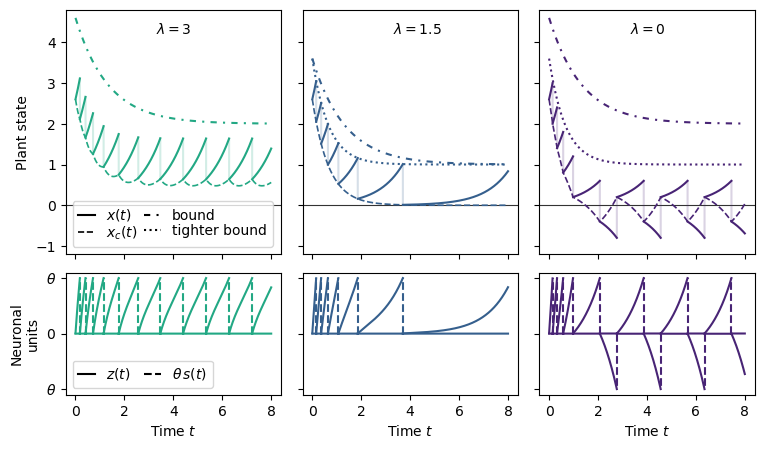

In [ ]:
ls_t_bound = 'dotted'
ls_bound = (0, (3,3,1,3))

# Set up grid for subplots
fig = plt.figure(figsize=(10, 5))

outer_gs = gridspec.GridSpec(1, 2, width_ratios=[1,0], figure=fig, wspace=.25)
gs_left = gridspec.GridSpecFromSubplotSpec(2, 3, subplot_spec=outer_gs[0], height_ratios=[2,1], hspace=0.1, wspace=0.1) 

color1 = cmap(0.1)
color2 = cmap(0.3)
color3 = cmap(0.6)

ax_x_1 = fig.add_subplot(gs_left[0,2])
ax_s_1 = fig.add_subplot(gs_left[1,2])

ax_x_2 = fig.add_subplot(gs_left[0,1])
ax_s_2 = fig.add_subplot(gs_left[1,1])

ax_x_3 = fig.add_subplot(gs_left[0,0])
ax_s_3 = fig.add_subplot(gs_left[1,0])

# Plot left subplot
ax_x_1.hlines(0, -1, 20, colors='0.2', lw=.8)
ax_x_1.plot(grid, x_cont_1, c=color1)
ax_x_1.plot(grid, x_jumps_1, c=color1, alpha=.2)
ax_x_1.plot(grid, upperbound_1_tight, c=color1, ls=ls_t_bound)
ax_x_1.plot(grid, upperbound_1, c=color1, ls=ls_bound)
ax_x_1.plot(grid, np.insert(x_c_1, 0, np.nan), c=color1, ls='dashed', lw=1.2)

# Plot middle subplot
ax_x_2.hlines(0, -1, 20, colors='0.2', lw=.8)
ax_x_2.plot(grid, x_cont_2, c=color2, label='$x(t)$')
ax_x_2.plot(grid, x_jumps_2, c=color2, alpha=.2)
ax_x_2.plot(grid, np.insert(x_c_2, 0, np.nan), c=color2, ls='dashed', lw=1.2, label='$x_c(t)$')
ax_x_2.plot(grid, upperbound_2, c=color2, ls=ls_bound, label='bound')
ax_x_2.plot(grid, upperbound_2_tight, c=color2, ls=ls_t_bound, label='tighter bound')

# Plot right subplot
ax_x_3.hlines(0, -1, 20, colors='0.2', lw=.8)
ax_x_3.plot(grid, x_cont_3, c=color3, label='$x(t)$')
ax_x_3.plot(grid, x_jumps_3, c=color3, alpha=.2)
ax_x_3.plot(grid, np.insert(x_c_3, 0, np.nan), c=color3, ls='dashed', lw=1.2, label='$x_c(t)$')
ax_x_3.plot(grid, upperbound_3, c=color3, ls=ls_bound, label='bound')
ax_x_3.plot(grid, upperbound_3+10, c='white', ls=ls_t_bound, label='tighter bound')

# Change visibility of tick labels
plt.setp(ax_x_3.get_xticklabels(), visible=False)
plt.setp(ax_x_2.get_xticklabels(), visible=False)
plt.setp(ax_x_1.get_xticklabels(), visible=False)
plt.setp(ax_x_1.get_yticklabels(), visible=False)
plt.setp(ax_x_2.get_yticklabels(), visible=False)

# Plot neuronal units for all subplots
ax_s_1.vlines(grid[np.where(s_1[:,0]>0)], 0, theta, ls='dashed', colors=color1)
ax_s_1.vlines(grid[np.where(s_1[:,1]>0)], 0, -theta, ls='dashed', colors=color1)
plt.setp(ax_s_1.get_yticklabels(), visible=False)
plt.setp(ax_s_2.get_yticklabels(), visible=False)

ax_s_1.set_yticks((-theta,0,theta))

ax_s_1.plot(grid, z_cont_1[:,0], c=color1, ls='solid')
ax_s_1.plot(grid, -z_cont_1[:,1], c=color1, ls='solid')

ax_s_2.plot(grid, z_cont_2[:,0], c=color2, ls='solid', label='$z(t)$')
ax_s_2.plot(grid, -z_cont_2[:,1], c=color2, ls='solid')

ax_s_2.vlines(grid[np.where(s_2[:,0]>0)], 0, theta, ls='dashed', colors=color2, label='$\\theta \\, s(t)$')
ax_s_2.vlines(grid[np.where(s_2[:,1]>0)], 0, -theta, ls='dashed', colors=color2)

ax_s_2.set_yticks((-theta,0,theta))
ax_s_2.set_yticklabels(('$\\theta$', '$0$', '$\\theta$'))

ax_s_3.plot(grid, z_cont_3[:,0], c=color3, ls='solid', label='$z(t)$')
ax_s_3.plot(grid, -z_cont_3[:,1], c=color3, ls='solid')

ax_s_3.vlines(grid[np.where(s_3[:,0]>0)], 0, theta, ls='dashed', colors=color3, label='$\\theta \\, s(t)$')
ax_s_3.vlines(grid[np.where(s_3[:,1]>0)], 0, -theta, ls='dashed', colors=color3)

ax_s_3.set_yticks((-theta,0,theta))
ax_s_3.set_yticklabels(('$\\theta$', '$0$', '$\\theta$'))

hl = 1.2

# Set legends
leg1 = ax_x_3.legend(loc=3, framealpha=.8, handlelength=hl, ncol=2, columnspacing=.5, labelspacing=0.1)
leg2 = ax_s_3.legend(loc=3, framealpha=.8, handlelength=hl, ncol=2, columnspacing=1)

for handle in leg2.legend_handles:
    if hasattr(handle, "set_color"):
        handle.set_color("black")
for handle in leg1.legend_handles:
    if hasattr(handle, "set_color"):
        handle.set_color("black")

ax_x_3.set_ylabel('Plant state', size=10)
ax_s_3.set_ylabel('Neuronal\nunits', size=10)
ax_s_1.set_xlabel('Time $t$', size=10, labelpad=4)
ax_s_2.set_xlabel('Time $t$', size=10, labelpad=4)
ax_s_3.set_xlabel('Time $t$', size=10, labelpad=4)

ax_x_1.set_ylim((-1.2, 4.8))
ax_x_2.set_ylim(ax_x_1.get_ylim())
ax_x_3.set_ylim(ax_x_1.get_ylim())
ax_s_2.set_ylim(ax_s_1.get_ylim())
ax_s_3.set_ylim(ax_s_1.get_ylim())

ax_x_1.set_xlim(ax_s_1.get_xlim())
ax_x_2.set_xlim(ax_s_2.get_xlim())
ax_x_3.set_xlim(ax_s_3.get_xlim())

pos_v = 4.2
ax_x_3.text(3.3,pos_v, f'$\\lambda = {leak_3}$', fontsize=10)
ax_x_2.text(3.3,pos_v, f'$\\lambda = {leak_2}$', fontsize=10)
ax_x_1.text(3.3,pos_v, f'$\\lambda = {leak_1}$', fontsize=10)

plt.savefig('../plots/figure2a.svg', dpi=400, bbox_inches='tight')